In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import regionmask
import seaborn as sns
from tqdm.auto import tqdm
from scipy import stats

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [2]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [3]:
import matplotlib as mpl

In [4]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [5]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [6]:
from functions import preproc_funcs as funcs

In [7]:
base_path    = "/g/data/if69/as8561/data/enso_tele_robustness"
smile_models = [
    'ACCESS-ESM1-5', 'CESM1-CAM5', 'CSIRO-Mk3-6-0',
    'CanESM2', 'CanESM5_p1', 'GFDL-CM3', 'GFDL-ESM2M',
    'GFDL-SPEAR-MED', 'MIROC6', 'MPI-ESM',
]
clim_base = slice('1960', '1990')
baseline  = slice('1950', '2014')
clim_fut  = slice('2070', '2100')

In [8]:
tas_obs   = xr.open_dataset(f"{base_path}/tas_obs.nc").load()
pr_rean   = xr.open_dataset(f"{base_path}/pr_rean.nc").load()
nino34    = xr.open_dataset(f"{base_path}/nino34_index_hadisst.nc").load()
tas_cmip6 = xr.open_dataset(f"{base_path}/cmip6/ts_ssp5.nc").load()
pr_cmip6  = xr.open_dataset(f"{base_path}/cmip6/pr_ssp5.nc").load()

In [9]:
tas_smile, pr_smile = {}, {}

for m in tqdm(smile_models, desc='Loading SMILEs'):
    ts = xr.open_dataset(f"{base_path}/smiles/{m}_ts.nc", decode_times=False)
    pr = xr.open_dataset(f"{base_path}/smiles/{m}_pr.nc", decode_times=False)
    ts = xr.decode_cf(ts).convert_calendar('standard', use_cftime=False)
    pr = xr.decode_cf(pr).convert_calendar('standard', use_cftime=False)
    tas_smile[m] = ts.load()
    pr_smile[m]  = pr.load()

Loading SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

In [10]:
# Obs/rean/cmip6 — already anomalised, just detrend
tas_obs['tas']  = funcs.detrend_rolling_window(tas_obs['tas'],  window_size=15)
pr_rean['pr']   = funcs.detrend_rolling_window(pr_rean['pr'],   window_size=15)
tas_cmip6['ts'] = funcs.detrend_rolling_window(tas_cmip6['ts'], window_size=15)
pr_cmip6['pr']  = funcs.detrend_rolling_window(pr_cmip6['pr'],  window_size=15)

# SMILEs — anomaly then detrend
for m in tqdm(smile_models, desc='Processing SMILEs'):
    tas_smile[m] = tas_smile[m].rename({list(tas_smile[m].data_vars)[0]: 'ts'})
    pr_smile[m]  = pr_smile[m].rename({list(pr_smile[m].data_vars)[0]:  'pr'})

    tas_smile[m]['ts'] = funcs.detrend_rolling_window(
        funcs.calc_anom_annual(tas_smile[m]['ts'], tas_smile[m]['ts'].sel(time=clim_base)),
        window_size=15
    )
    pr_smile[m]['pr'] = funcs.detrend_rolling_window(
        funcs.calc_anom_annual(pr_smile[m]['pr'], pr_smile[m]['pr'].sel(time=clim_base)),
        window_size=15
    )

Processing SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

In [11]:
nino34_lat = slice(-5, 5)
nino34_lon = slice(190, 240)

nino34_obs          = nino34.rename({'tos': 'ts'})
nino34_obs['ts']    = funcs.detrend_rolling_window(nino34_obs['ts'], window_size=15)
nino34_cmip6        = tas_cmip6['ts'].sel(lat=nino34_lat, lon=nino34_lon).mean(['lat', 'lon'])
nino34_smile        = {m: tas_smile[m]['ts'].sel(lat=nino34_lat, lon=nino34_lon).mean(['lat', 'lon'])
                       for m in smile_models}

In [12]:
obs_std   = float(nino34_obs['ts'].sel(time=baseline).std('time'))
cmip6_std = nino34_cmip6.sel(time=baseline).std('time')

cond_en_obs  = nino34_obs['ts'] >  0.5 * obs_std
cond_ln_obs  = nino34_obs['ts'] < -0.5 * obs_std
cond_neu_obs = (nino34_obs['ts'] >= -0.25 * obs_std) & \
               (nino34_obs['ts'] <=  0.25 * obs_std)

cond_en_cmip6  = nino34_cmip6 >  0.5 * cmip6_std
cond_ln_cmip6  = nino34_cmip6 < -0.5 * cmip6_std
cond_neu_cmip6 = (nino34_cmip6 >= -0.25 * cmip6_std) & \
                 (nino34_cmip6 <=  0.25 * cmip6_std)

cond_en_smile, cond_ln_smile, cond_neu_smile = {}, {}, {}
for m in smile_models:
    smile_std         = nino34_smile[m].sel(time=baseline).std('time')
    cond_en_smile[m]  = nino34_smile[m] >  0.5 * smile_std
    cond_ln_smile[m]  = nino34_smile[m] < -0.5 * smile_std
    cond_neu_smile[m] = (nino34_smile[m] >= -0.25 * smile_std) & \
                        (nino34_smile[m] <=  0.25 * smile_std)

In [13]:
# --- AR6 masks ---
ar6_regions = regionmask.defined_regions.ar6.land
all_abbrevs = {r.abbrev: r.number for r in ar6_regions}

# --- Land masks ---
land_mask_obs   = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(tas_obs)
land_mask_rean  = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_rean)
land_mask_cmip6 = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(tas_cmip6)
land_mask_smile = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(tas_smile['ACCESS-ESM1-5'])

# --- AR6 masks with land mask applied ---
ar6_mask_obs   = regionmask.defined_regions.ar6.land.mask_3D(tas_obs.where(land_mask_obs))
ar6_mask_rean  = regionmask.defined_regions.ar6.land.mask_3D(pr_rean.where(land_mask_rean))
ar6_mask_cmip6 = regionmask.defined_regions.ar6.land.mask_3D(tas_cmip6.where(land_mask_cmip6))
ar6_mask_smile = regionmask.defined_regions.ar6.land.mask_3D(tas_smile['ACCESS-ESM1-5'].where(land_mask_smile))

# --- Updated weighted regional mean function ---
def weighted_region(da, mask_3d, region_idx):
    """
    mask_3d: boolean (region, lat, lon) from mask_3D
    region_idx: integer index into mask_3d.region
    """
    weights  = np.cos(np.deg2rad(da.lat))
    region_mask = mask_3d.isel(region=region_idx)
    return da.where(region_mask).weighted(weights).mean(['lat', 'lon'])

In [14]:
tas_obs_reg, pr_rean_reg, tas_cmip6_reg, pr_cmip6_reg = {}, {}, {}, {}

for idx, (abbrev, rnum) in enumerate(tqdm(all_abbrevs.items(), desc='Obs/CMIP6 regions')):
    
    # find region index in mask_3D
    obs_idx   = int(np.where(ar6_mask_obs.region == rnum)[0])
    rean_idx  = int(np.where(ar6_mask_rean.region == rnum)[0])
    cmip6_idx = int(np.where(ar6_mask_cmip6.region == rnum)[0])

    tas_obs_reg[abbrev]   = weighted_region(tas_obs['tas'],   ar6_mask_obs,   obs_idx)
    
    da = weighted_region(pr_rean['pr'], ar6_mask_rean, rean_idx)
    pr_rean_reg[abbrev]   = da / float(da.std('time', skipna=True))

    tas_cmip6_reg[abbrev] = weighted_region(tas_cmip6['ts'], ar6_mask_cmip6, cmip6_idx)

    da = weighted_region(pr_cmip6['pr'], ar6_mask_cmip6, cmip6_idx)
    pr_cmip6_reg[abbrev]  = da / da.std('time', skipna=True)

# --- SMILEs ---
tas_smile_reg, pr_smile_reg = {}, {}

for m in tqdm(smile_models, desc='SMILE regions'):
    tas_smile_reg[m] = {}
    pr_smile_reg[m]  = {}
    for abbrev, rnum in all_abbrevs.items():
        smile_idx = int(np.where(ar6_mask_smile.region == rnum)[0])
        
        tas_smile_reg[m][abbrev] = weighted_region(tas_smile[m]['ts'], ar6_mask_smile, smile_idx)
        
        da = weighted_region(pr_smile[m]['pr'], ar6_mask_smile, smile_idx)
        pr_smile_reg[m][abbrev]  = da / da.std('time', skipna=True)

Obs/CMIP6 regions:   0%|          | 0/46 [00:00<?, ?it/s]

/scratch/gb02/as8561/tmp/ipykernel_2020706/4135298817.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  obs_idx   = int(np.where(ar6_mask_obs.region == rnum)[0])
/scratch/gb02/as8561/tmp/ipykernel_2020706/4135298817.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  rean_idx  = int(np.where(ar6_mask_rean.region == rnum)[0])
/scratch/gb02/as8561/tmp/ipykernel_2020706/4135298817.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cmip6_idx = int(np.where(ar6_mask_

SMILE regions:   0%|          | 0/10 [00:00<?, ?it/s]

/scratch/gb02/as8561/tmp/ipykernel_2020706/4135298817.py:27: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  smile_idx = int(np.where(ar6_mask_smile.region == rnum)[0])
/scratch/gb02/as8561/tmp/ipykernel_2020706/4135298817.py:27: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  smile_idx = int(np.where(ar6_mask_smile.region == rnum)[0])
/scratch/gb02/as8561/tmp/ipykernel_2020706/4135298817.py:27: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  smile_idx = int(np.where(ar6

In [15]:
# def rolling_composite(da, cond_en, cond_ln,
#                        start=1900, end=2014, duration=30, gap=1):
#     en_means, ln_means, yrs = [], [], []
    
#     for yr in range(start, end - duration + 2, gap):
#         win        = slice(str(yr), str(yr + duration - 1))
#         en_sub     = da.sel(time=win).where(cond_en.sel(time=win), drop=True)
#         ln_sub     = da.sel(time=win).where(cond_ln.sel(time=win), drop=True)
        
#         en_means.append(float(en_sub.mean('time', skipna=True))
#                         if en_sub.sizes['time'] > 2 else np.nan)
#         ln_means.append(float(ln_sub.mean('time', skipna=True))
#                         if ln_sub.sizes['time'] > 2 else np.nan)
#         yrs.append(yr + duration - 1)
    
#     return np.array(yrs), np.array(en_means), np.array(ln_means)



def regional_composite_bootstrap(da, cond_en, cond_ln,
                                 duration=30, block=3, n_boot=1000,
                                 seed=0, min_years=60):
    """
    Block-bootstrap sampling distribution of the duration-year EN and LN
    composite means for a single regional time series.

    Returns (en_boot, ln_boot, n_valid_years):
      en_boot, ln_boot : arrays of length n_boot (the bootstrap distribution
                         of the composite mean); std of these is the noise.
      n_valid_years    : count of finite years in the aligned record.
    """
    rng = np.random.default_rng(seed)

    # Align region series with ENSO conditions (handles 1849–2023 vs 1900–2014)
    da_a, en_a, ln_a = xr.align(da, cond_en, cond_ln, join='inner')

    v   = da_a.values            # (time,)
    en  = en_a.values.astype(bool)
    ln  = ln_a.values.astype(bool)
    nt  = v.shape[0]

    n_valid = int(np.isfinite(v).sum())

    n_blocks  = int(np.ceil(duration / block))
    max_start = nt - block

    en_boot = np.full(n_boot, np.nan)
    ln_boot = np.full(n_boot, np.nan)

    for b in range(n_boot):
        starts = rng.integers(0, max_start + 1, size=n_blocks)
        idx    = np.concatenate([np.arange(s, s + block) for s in starts])[:duration]

        sub    = v[idx]
        en_sel = en[idx]
        ln_sel = ln[idx]

        if en_sel.sum() >= 2:
            en_boot[b] = np.nanmean(sub[en_sel])
        if ln_sel.sum() >= 2:
            ln_boot[b] = np.nanmean(sub[ln_sel])

    return en_boot, ln_boot, n_valid

In [16]:
# def comp_mean(da, cond):
#     """Composite mean — NaN if no events."""
#     sub = da.where(cond, drop=True)
#     if sub.sizes['time'] < 2:
#         return np.nan
#     return float(sub.mean('time', skipna=True))

In [38]:
records = []

for abbrev in tqdm(all_abbrevs.keys(), desc='Regional composites'):

    # --- Obs ---
    tas_obs_r = tas_obs_reg[abbrev]
    pr_rean_r = pr_rean_reg[abbrev]

    tas_en_obs_base = float(tas_obs_r.sel(time=baseline).where(cond_en_obs.sel(time=baseline), drop=True).mean('time', skipna=True))
    tas_ln_obs_base = float(tas_obs_r.sel(time=baseline).where(cond_ln_obs.sel(time=baseline), drop=True).mean('time', skipna=True))
    pr_en_obs_base  = float(pr_rean_r.sel(time=baseline).where(cond_en_obs.sel(time=baseline), drop=True).mean('time', skipna=True))
    pr_ln_obs_base  = float(pr_rean_r.sel(time=baseline).where(cond_ln_obs.sel(time=baseline), drop=True).mean('time', skipna=True))

    # --- Block-bootstrap composite noise (replaces rolling_composite) ---
    tas_en_roll, tas_ln_roll, tas_nvalid = regional_composite_bootstrap(
        tas_obs_r, cond_en_obs, cond_ln_obs)
    pr_en_roll,  pr_ln_roll,  pr_nvalid  = regional_composite_bootstrap(
        pr_rean_r, cond_en_obs, cond_ln_obs)

    # --- CMIP6 ---
    tas_c = tas_cmip6_reg[abbrev]
    pr_c  = pr_cmip6_reg[abbrev]

    tas_en_cmip6_base = float(tas_c.sel(time=baseline).where(cond_en_cmip6.sel(time=baseline)).mean(['time','model'], skipna=True))
    tas_ln_cmip6_base = float(tas_c.sel(time=baseline).where(cond_ln_cmip6.sel(time=baseline)).mean(['time','model'], skipna=True))
    tas_en_cmip6_fut  = float(tas_c.sel(time=clim_fut).where(cond_en_cmip6.sel(time=clim_fut)).mean(['time','model'], skipna=True))
    tas_ln_cmip6_fut  = float(tas_c.sel(time=clim_fut).where(cond_ln_cmip6.sel(time=clim_fut)).mean(['time','model'], skipna=True))

    pr_en_cmip6_base  = float(pr_c.sel(time=baseline).where(cond_en_cmip6.sel(time=baseline)).mean(['time','model'], skipna=True))
    pr_ln_cmip6_base  = float(pr_c.sel(time=baseline).where(cond_ln_cmip6.sel(time=baseline)).mean(['time','model'], skipna=True))
    pr_en_cmip6_fut   = float(pr_c.sel(time=clim_fut).where(cond_en_cmip6.sel(time=clim_fut)).mean(['time','model'], skipna=True))
    pr_ln_cmip6_fut   = float(pr_c.sel(time=clim_fut).where(cond_ln_cmip6.sel(time=clim_fut)).mean(['time','model'], skipna=True))

    # --- SMILE ---
    tas_en_base_s, tas_ln_base_s = [], []
    tas_en_fut_s,  tas_ln_fut_s  = [], []
    pr_en_base_s,  pr_ln_base_s  = [], []
    pr_en_fut_s,   pr_ln_fut_s   = [], []
    tas_en_iv_s,   tas_ln_iv_s   = [], []
    pr_en_iv_s,    pr_ln_iv_s    = [], []

    for m in smile_models:
        tas_s = tas_smile_reg[m][abbrev]
        pr_s  = pr_smile_reg[m][abbrev]

        tas_en_b = tas_s.sel(time=baseline).where(cond_en_smile[m].sel(time=baseline)).mean('time', skipna=True)
        tas_ln_b = tas_s.sel(time=baseline).where(cond_ln_smile[m].sel(time=baseline)).mean('time', skipna=True)
        tas_en_f = tas_s.sel(time=clim_fut).where(cond_en_smile[m].sel(time=clim_fut)).mean('time', skipna=True)
        tas_ln_f = tas_s.sel(time=clim_fut).where(cond_ln_smile[m].sel(time=clim_fut)).mean('time', skipna=True)

        pr_en_b  = pr_s.sel(time=baseline).where(cond_en_smile[m].sel(time=baseline)).mean('time', skipna=True)
        pr_ln_b  = pr_s.sel(time=baseline).where(cond_ln_smile[m].sel(time=baseline)).mean('time', skipna=True)
        pr_en_f  = pr_s.sel(time=clim_fut).where(cond_en_smile[m].sel(time=clim_fut)).mean('time', skipna=True)
        pr_ln_f  = pr_s.sel(time=clim_fut).where(cond_ln_smile[m].sel(time=clim_fut)).mean('time', skipna=True)

        tas_en_iv_s.append(float(tas_en_b.std('model', skipna=True)))
        tas_ln_iv_s.append(float(tas_ln_b.std('model', skipna=True)))
        pr_en_iv_s.append(float(pr_en_b.std('model',   skipna=True)))
        pr_ln_iv_s.append(float(pr_ln_b.std('model',   skipna=True)))

        tas_en_base_s.append(float(tas_en_b.mean('model', skipna=True)))
        tas_ln_base_s.append(float(tas_ln_b.mean('model', skipna=True)))
        tas_en_fut_s.append(float(tas_en_f.mean('model',  skipna=True)))
        tas_ln_fut_s.append(float(tas_ln_f.mean('model',  skipna=True)))
        pr_en_base_s.append(float(pr_en_b.mean('model',   skipna=True)))
        pr_ln_base_s.append(float(pr_ln_b.mean('model',   skipna=True)))
        pr_en_fut_s.append(float(pr_en_f.mean('model',    skipna=True)))
        pr_ln_fut_s.append(float(pr_ln_f.mean('model',    skipna=True)))

    records.append(dict(
        abbrev               = abbrev,
        name                 = ar6_regions[all_abbrevs[abbrev]].name,
        # Obs
        tas_en_obs_base      = tas_en_obs_base,
        tas_ln_obs_base      = tas_ln_obs_base,
        pr_en_obs_base       = pr_en_obs_base,
        pr_ln_obs_base       = pr_ln_obs_base,
        tas_en_roll          = tas_en_roll,
        tas_ln_roll          = tas_ln_roll,
        pr_en_roll           = pr_en_roll,
        pr_ln_roll           = pr_ln_roll,
        # Validity (≥ 60 valid years)
        tas_valid            = tas_nvalid >= 60,
        pr_valid             = pr_nvalid  >= 60,
        tas_nvalid           = tas_nvalid,
        pr_nvalid            = pr_nvalid,
        # CMIP6
        tas_en_cmip6_base    = tas_en_cmip6_base,
        tas_ln_cmip6_base    = tas_ln_cmip6_base,
        tas_en_cmip6_fut     = tas_en_cmip6_fut,
        tas_ln_cmip6_fut     = tas_ln_cmip6_fut,
        pr_en_cmip6_base     = pr_en_cmip6_base,
        pr_ln_cmip6_base     = pr_ln_cmip6_base,
        pr_en_cmip6_fut      = pr_en_cmip6_fut,
        pr_ln_cmip6_fut      = pr_ln_cmip6_fut,
        # SMILE IV
        tas_en_smile_iv      = np.nanmean(tas_en_iv_s),
        tas_ln_smile_iv      = np.nanmean(tas_ln_iv_s),
        pr_en_smile_iv       = np.nanmean(pr_en_iv_s),
        pr_ln_smile_iv       = np.nanmean(pr_ln_iv_s),
        # SMILE baseline
        tas_en_smile_base    = np.nanmean(tas_en_base_s),
        tas_ln_smile_base    = np.nanmean(tas_ln_base_s),
        pr_en_smile_base     = np.nanmean(pr_en_base_s),
        pr_ln_smile_base     = np.nanmean(pr_ln_base_s),
        # SMILE future
        tas_en_smile_fut_val = np.nanmean(tas_en_fut_s),
        tas_ln_smile_fut_val = np.nanmean(tas_ln_fut_s),
        pr_en_smile_fut_val  = np.nanmean(pr_en_fut_s),
        pr_ln_smile_fut_val  = np.nanmean(pr_ln_fut_s),
    ))

df = pd.DataFrame(records)
print(df[['abbrev', 'name', 'tas_nvalid', 'pr_nvalid', 'tas_valid', 'pr_valid']].head(10))

Regional composites:   0%|          | 0/46 [00:00<?, ?it/s]

/scratch/gb02/as8561/tmp/ipykernel_2020706/3556441782.py:59: RuntimeWarning: Mean of empty slice
  en_boot[b] = np.nanmean(sub[en_sel])
/scratch/gb02/as8561/tmp/ipykernel_2020706/3556441782.py:61: RuntimeWarning: Mean of empty slice
  ln_boot[b] = np.nanmean(sub[ln_sel])


  abbrev               name  tas_nvalid  pr_nvalid  tas_valid  pr_valid
0    GIC  Greenland/Iceland         115        115       True      True
1    NWN  N.W.North-America         115        115       True      True
2    NEN  N.E.North-America         115        115       True      True
3    WNA    W.North-America         115        115       True      True
4    CNA    C.North-America         115        115       True      True
5    ENA    E.North-America         115        115       True      True
6    NCA  N.Central-America         115        115       True      True
7    SCA  S.Central-America         115        115       True      True
8    CAR          Caribbean         115        115       True      True
9    NWS  N.W.South-America         115        115       True      True


In [39]:
from scipy import stats

def ttest_cmip6(abbrev, phase, var):
    reg        = tas_cmip6_reg[abbrev] if var == 'tas' else pr_cmip6_reg[abbrev]
    cond_phase = cond_en_cmip6 if phase == 'en' else cond_ln_cmip6

    base = reg.sel(time=baseline).where(cond_phase.sel(time=baseline)).mean('time', skipna=True).values
    fut  = reg.sel(time=clim_fut).where(cond_phase.sel(time=clim_fut)).mean('time',  skipna=True).values

    mask = ~(np.isnan(base) | np.isnan(fut))
    if mask.sum() < 3:
        return np.nan
    _, p = stats.ttest_ind(fut[mask], base[mask], equal_var=False)
    return p

In [40]:
threshold = 1.5

for phase in ['en', 'ln']:
    for var in ['tas', 'pr']:

        # SMILE forced change — signal for both CNR tests
        smile_change = df[f'{var}_{phase}_smile_fut_val'] - df[f'{var}_{phase}_smile_base']

        # --- t-test ---
        df[f'{var}_{phase}_ttest'] = [ttest_cmip6(r, phase, var) for r in df.abbrev]

        # --- CNR obs — SMILE forced change vs bootstrap composite noise ---
        obs_noise = df[f'{var}_{phase}_roll'].apply(np.nanstd)
        df[f'{var}_{phase}_snr_obs'] = smile_change / obs_noise

        # --- CNR IV — SMILE forced change vs SMILE IV ---
        df[f'{var}_{phase}_snr_iv'] = smile_change / df[f'{var}_{phase}_smile_iv']

        # --- Robustness flags ---
        df[f'{var}_{phase}_rob_ttest'] = df[f'{var}_{phase}_ttest'] < 0.05
        df[f'{var}_{phase}_rob_obs']   = df[f'{var}_{phase}_snr_obs'].abs() >= threshold
        df[f'{var}_{phase}_rob_iv']    = df[f'{var}_{phase}_snr_iv'].abs()  >= threshold

        # --- Mask CNR_obs where region is data-sparse (< 60 valid years) ---
        valid_col = f'{var}_valid'
        df.loc[~df[valid_col], f'{var}_{phase}_snr_obs'] = np.nan
        df.loc[~df[valid_col], f'{var}_{phase}_rob_obs'] = False  # or np.nan if you prefer "untested"

print(df[['abbrev', 'pr_en_rob_ttest', 'pr_en_rob_obs', 'pr_en_rob_iv',
          'pr_valid']].head(10))

  abbrev  pr_en_rob_ttest  pr_en_rob_obs  pr_en_rob_iv  pr_valid
0    GIC             True          False         False      True
1    NWN            False          False          True      True
2    NEN            False          False          True      True
3    WNA             True          False          True      True
4    CNA             True          False         False      True
5    ENA            False          False         False      True
6    NCA             True          False          True      True
7    SCA             True          False          True      True
8    CAR             True          False         False      True
9    NWS            False          False         False      True


In [41]:
# # Initialise array columns as object dtype to hold bootstrap distributions
# for col in ['pr_en_roll_gpcc', 'pr_ln_roll_gpcc']:
#     df[col] = None
#     df[col] = df[col].astype(object)

# for abbrev in tqdm(df.abbrev, desc='PR obs (GPCC) bootstrap'):
#     da = pr_obs_reg[abbrev]

#     en_boot, ln_boot, nvalid = regional_composite_bootstrap(
#         da, cond_en_obs, cond_ln_obs)

#     en_base = float(da.sel(time=baseline).where(cond_en_obs.sel(time=baseline), drop=True).mean('time', skipna=True))
#     ln_base = float(da.sel(time=baseline).where(cond_ln_obs.sel(time=baseline), drop=True).mean('time', skipna=True))

#     idx = df.index[df.abbrev == abbrev][0]
#     df.loc[idx, 'pr_en_obs_base_gpcc'] = en_base
#     df.loc[idx, 'pr_ln_obs_base_gpcc'] = ln_base
#     df.loc[idx, 'pr_valid_gpcc']       = nvalid >= 60
#     df.loc[idx, 'pr_nvalid_gpcc']      = nvalid
#     df.at[idx, 'pr_en_roll_gpcc'] = en_boot
#     df.at[idx, 'pr_ln_roll_gpcc'] = ln_boot

# print(df[['abbrev', 'pr_nvalid_gpcc', 'pr_valid_gpcc',
#           'pr_en_obs_base_gpcc']].head())

In [42]:
df.to_csv('/g/data/if69/as8561/data/enso_tele_robustness/res/regional_summary_df.csv')

In [12]:
df = pd.read_csv('/g/data/if69/as8561/data/enso_tele_robustness/res/regional_summary_df.csv')
df = df.drop(columns=['Unnamed: 0'])

In [13]:
# # def parse_array(val):
# #     if isinstance(val, str):
# #         # Strip brackets and whitespace, split, convert to float
# #         return np.fromstring(val.strip('[]'), sep=' ')
# #     return np.asarray(val, dtype=float)

# # # Apply to all roll columns
# # for phase in ['en', 'ln']:
# #     for var in ['tas', 'pr']:
# #         df[f'{var}_{phase}_roll'] = df[f'{var}_{phase}_roll'].apply(parse_array)



# def parse_array(val):
#     if isinstance(val, str):
#         cleaned = val.strip('[]').replace('\n', ' ')
#         return np.array([float(x) for x in cleaned.split()])
#     return np.asarray(val, dtype=float)

# # Parse all roll columns
# for col in ['pr_en_roll', 'pr_ln_roll', 'tas_en_roll', 'tas_ln_roll', 'pr_en_roll_gpcc', 'pr_ln_roll_gpcc']:
#     df[col] = df[col].apply(parse_array)

In [14]:
print(df.head())

  abbrev               name  tas_en_obs_base  tas_ln_obs_base  pr_en_obs_base  \
0    GIC  Greenland/Iceland        -0.021767        -0.055959       -0.218100   
1    NWN  N.W.North-America         0.289513        -0.382260       -0.389554   
2    NEN  N.E.North-America         0.034469         0.184053       -0.160444   
3    WNA    W.North-America         0.140230        -0.217862        0.248112   
4    CNA    C.North-America        -0.086290         0.097368        0.304981   

   pr_ln_obs_base                                        tas_en_roll  \
0       -0.029794  [-7.96188935e-02 -9.87772892e-02 -4.27418938e-...   
1       -0.238858  [ 4.41610800e-01  9.13068431e-02  4.33536199e-...   
2       -0.008203  [ 4.07672087e-02  2.56135239e-02  1.79882601e-...   
3        0.028755  [ 1.40540870e-01 -6.69181946e-02  1.23051145e-...   
4       -0.193614  [ 1.03952488e-02 -2.71157853e-01 -4.67819622e-...   

                                         tas_ln_roll  \
0  [ 9.20512974e-03 -8.0

In [15]:
# def plot_regional_summary_combined(df, var, title):
    
#     # Sort by EN CMIP6 baseline — same order for both panels
#     sort_col  = f'{var}_en_cmip6_base'
#     df_sorted = df.sort_values(sort_col).reset_index(drop=True)
#     n         = len(df_sorted)
#     x         = np.arange(n)

#     def get_color_cmip6(row, phase):
#         return 'tab:red' if row[f'{var}_{phase}_rob_ttest'] else 'lightgrey'

#     def get_color_smile(row, phase):
#         iv  = row[f'{var}_{phase}_rob_iv']
#         obs = row[f'{var}_{phase}_rob_obs']
#         if iv and obs:  return 'tab:red'
#         elif iv:        return 'tab:orange'
#         else:           return 'lightgrey'

#     fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

#     for ax, phase, phase_label in zip(axes, ['en', 'ln'], ['El Niño', 'La Niña']):

#         cmip6_colors = [get_color_cmip6(row, phase) for _, row in df_sorted.iterrows()]
#         smile_colors = [get_color_smile(row, phase) for _, row in df_sorted.iterrows()]

#         # --- Obs rolling boxplot ---
#         # roll_data = [arr[~np.isnan(arr)] for arr in df_sorted[f'{var}_{phase}_roll'].tolist()]
#         roll_data = [np.asarray(arr, dtype=float)[~np.isnan(np.asarray(arr, dtype=float))] 
#              for arr in df_sorted[f'{var}_{phase}_roll'].tolist()]
#         ax.boxplot(
#             roll_data,
#             positions    = x,
#             widths       = 0.5,
#             patch_artist = True,
#             boxprops     = dict(facecolor='lightgrey', alpha=0.7),
#             medianprops  = dict(color='k', lw=1.5),
#             whiskerprops = dict(lw=1.0),
#             flierprops   = dict(marker='.', markersize=2, alpha=0.3),
#             whis         = [5, 95],
#             showfliers   = False,
#             zorder       = 2,
#         )

#         # --- SMILE IV shading ---
#         smile_base = df_sorted[f'{var}_{phase}_smile_base'].values
#         iv_vals    = df_sorted[f'{var}_{phase}_smile_iv'].values
#         ax.fill_between(x,
#                         smile_base - iv_vals,
#                         smile_base + iv_vals,
#                         color='steelblue', alpha=0.2,
#                         zorder=1)

#         # --- CMIP6 baseline diamond ---
#         cmip6_base = df_sorted[f'{var}_{phase}_cmip6_base'].values
#         ax.scatter(x, cmip6_base,
#                    marker='D', s=40, color='k', zorder=5)

#         # --- CMIP6 future circle ---
#         ax.scatter(x - 0.15, df_sorted[f'{var}_{phase}_cmip6_fut'].values,
#                    marker='o', s=60, color=cmip6_colors,
#                    edgecolors='k', linewidths=0.5, zorder=6)

#         # --- SMILE future triangle ---
#         ax.scatter(x + 0.15, df_sorted[f'{var}_{phase}_smile_fut_val'].values,
#                    marker='^', s=70, color=smile_colors,
#                    edgecolors='k', linewidths=0.5, zorder=6)

#         ax.axhline(0, color='k', lw=0.5, linestyle='-')
#         ax.set_xlim(-1.5, 46.5)
#         ax.set_ylabel('Temp. anomaly (°C)' if var == 'tas' 
#                       else 'Precip. anomaly (mm/month std$^{-1}$)')
#         ax.set_title(f'{phase_label}')
#         plt.sca(ax)
#         plot_decorator()

#         # Legend on first panel only
#         if phase == 'en':
#             from matplotlib.patches import Patch
#             from matplotlib.lines import Line2D
#             legend_elements = [
#                 Patch(facecolor='lightgrey', alpha=0.7,
#                       label='Obs 30-yr sampling range (5th–95th)'),
#                 Patch(facecolor='steelblue', alpha=0.2,
#                       label='SMILE IV (±1σ around SMILE baseline)'),
#                 Line2D([0], [0], marker='D', color='k',
#                        linestyle='None', markersize=6,
#                        label='CMIP6 baseline MMM'),
#                 Line2D([0], [0], marker='o', color='tab:red',
#                        linestyle='None', markersize=6,
#                        markeredgecolor='k', label='CMIP6 future — t-test robust'),
#                 Line2D([0], [0], marker='o', color='lightgrey',
#                        linestyle='None', markersize=6,
#                        markeredgecolor='k', label='CMIP6 future — not robust'),
#                 Line2D([0], [0], marker='^', color='tab:red',
#                        linestyle='None', markersize=6,
#                        markeredgecolor='k', label='SMILE future — IV + obs S/N robust'),
#                 Line2D([0], [0], marker='^', color='tab:orange',
#                        linestyle='None', markersize=6,
#                        markeredgecolor='k', label='SMILE future — IV only robust'),
#                 Line2D([0], [0], marker='^', color='lightgrey',
#                        linestyle='None', markersize=6,
#                        markeredgecolor='k', label='SMILE future — not robust'),
#             ]
#             # ax.legend(handles=legend_elements, fontsize=10,
#             #           ncol=2, loc='lower right', frameon=False)

#     # Shared x-axis labels on bottom panel only
#     axes[1].set_xticks(x)
#     axes[1].set_xticklabels(df_sorted['abbrev'].tolist(),
#                              rotation=30, ha='center', fontsize=12,
#                              rotation_mode='anchor')
#     ticks = axes[1].xaxis.get_major_ticks()
#     for i, tick in enumerate(ticks):
#         if i % 2 == 0:
#             tick.set_pad(30)
#             tick.tick1line.set_markersize(30)
#         else:
#             tick.set_pad(2)
#             tick.tick1line.set_markersize(5)

#     fig.suptitle(title, fontsize=13, y=1.01)
#     plt.tight_layout()
#     # return fig





In [16]:
# plot_regional_summary_combined(df, var='tas', title='Temperature ENSO composite change (2070–2100)')

In [17]:
# plot_regional_summary_combined(df, var='pr',  title='Precipitation ENSO composite change (2070–2100)')

In [18]:
# def plot_obs_comparison(df, phase, title):
    
#     sort_col  = f'pr_{phase}_cmip6_base'
#     df_sorted = df.sort_values(sort_col).reset_index(drop=True)
#     n         = len(df_sorted)
#     x         = np.arange(n)

#     fig, ax = plt.subplots(figsize=(14, 5))

#     # --- Reanalysis rolling boxplot (left offset) ---
#     rean_data = [np.asarray(arr, dtype=float)[~np.isnan(np.asarray(arr, dtype=float))]
#                  for arr in df_sorted[f'pr_{phase}_roll'].tolist()]
#     ax.boxplot(
#         rean_data,
#         positions    = x - 0.2,
#         widths       = 0.35,
#         patch_artist = True,
#         boxprops     = dict(facecolor='steelblue', alpha=0.5),
#         medianprops  = dict(color='k', lw=1.2),
#         whiskerprops = dict(lw=0.8),
#         whis         = [5, 95],
#         showfliers   = False,
#         zorder       = 2,
#     )

#     # --- GPCC obs rolling boxplot (right offset) ---
#     gpcc_data = [np.asarray(arr, dtype=float)[~np.isnan(np.asarray(arr, dtype=float))]
#                  for arr in df_sorted[f'pr_{phase}_roll_gpcc'].tolist()]
#     ax.boxplot(
#         gpcc_data,
#         positions    = x + 0.2,
#         widths       = 0.35,
#         patch_artist = True,
#         boxprops     = dict(facecolor='tab:orange', alpha=0.5),
#         medianprops  = dict(color='k', lw=1.2),
#         whiskerprops = dict(lw=0.8),
#         whis         = [5, 95],
#         showfliers   = False,
#         zorder       = 2,
#     )

#     ax.axhline(0, color='k', lw=0.5)
#     ax.set_xlim(-1.5, 46.5)
#     ax.set_ylabel('Precip. anomaly (mm/month std$^{-1}$)')
#     ax.set_title(f'{title}')

#     from matplotlib.patches import Patch
#     legend_elements = [
#         Patch(facecolor='steelblue',  alpha=0.5, label='Reanalysis 30-yr sampling'),
#         Patch(facecolor='tab:orange', alpha=0.5, label='GPCC obs 30-yr sampling'),
#     ]
#     ax.legend(handles=legend_elements, fontsize=10, frameon=False)

#     plt.sca(ax)
#     plot_decorator()

#     # X labels with alternating tick length
#     ax.set_xticks(x)
#     ax.set_xticklabels(df_sorted['abbrev'].tolist(),
#                        rotation=30, ha='center', fontsize=12,
#                        rotation_mode='anchor')
#     ticks = ax.xaxis.get_major_ticks()
#     for i, tick in enumerate(ticks):
#         if i % 2 == 0:
#             tick.set_pad(30)
#             tick.tick1line.set_markersize(30)
#         else:
#             tick.set_pad(2)
#             tick.tick1line.set_markersize(5)

#     plt.tight_layout()
#     # return fig

# plot_obs_comparison(df, 'en', r'El Niño')
# plot_obs_comparison(df, 'ln', r'La Niña')

In [24]:
def plot_snr_mirror(df, var, title):

    sort_col  = f'{var}_en_snr_obs'
    df_sorted = df.sort_values(sort_col, key=np.abs, ascending=False).reset_index(drop=True)
    # n         = len(df_sorted)
    # x         = np.arange(n)
    # After sorting, optionally drop data-sparse regions
    valid_col = f'{var}_valid'
    df_sorted = df_sorted[df_sorted[valid_col]].reset_index(drop=True)
    n = len(df_sorted)
    x = np.arange(n)

    fig, ax = plt.subplots(figsize=(12, 7))

    ymax    = 6.0
    # gutter  = 0.45   # extra space beyond ymax for the amp/damp arrow lane

    # --- Light shading for |SNR| < 1.5 on both sides ---
    ax.axhspan(-1.5, 1.5, color='lightgrey', alpha=0.25, zorder=0)

    for phase, color, sign in [('en', 'tab:red', 1), ('ln', 'tab:blue', -1)]:

        snr_obs = np.abs(df_sorted[f'{var}_{phase}_snr_obs'].values) * sign
        snr_iv  = np.abs(df_sorted[f'{var}_{phase}_snr_iv'].values)  * sign
        ttest   = df_sorted[f'{var}_{phase}_rob_ttest'].values
        rob_obs = df_sorted[f'{var}_{phase}_rob_obs'].values
        rob_iv  = df_sorted[f'{var}_{phase}_rob_iv'].values
        snr_both_robust = rob_obs & rob_iv

        # --- t-test as half-column shading (top half for EN, bottom for LN) ---
        for i in range(n):
            if ttest[i]:
                y0, y1 = (0, ymax) if sign > 0 else (-ymax, 0)
                ax.axvspan(x[i] - 0.4, x[i] + 0.4,
                           ymin=(y0 + ymax) / (2 * ymax),
                           ymax=(y1 + ymax) / (2 * ymax),
                           color=color, alpha=0.07, zorder=0)

        # Connecting line
        for i in range(n):
            ax.plot([x[i], x[i]], [snr_obs[i], snr_iv[i]],
                    color=color, lw=1.0, alpha=0.4, zorder=2)

        # SNR vs obs — circle
        ax.scatter(x, snr_obs, marker='o', s=90, color=color,
                   edgecolors='k', linewidths=0.6, zorder=4)
        # SNR vs IV — diamond
        ax.scatter(x, snr_iv, marker='D', s=70, color=color,
                   edgecolors='k', linewidths=0.6, alpha=0.55, zorder=4)

        # --- Amp/damp arrows in dedicated gutter lane beyond data ---
        fut_mag  = np.abs(df_sorted[f'{var}_{phase}_smile_fut_val'].values)
        base_mag = np.abs(df_sorted[f'{var}_{phase}_smile_base'].values)
        y_pos    = 5.5 * sign
        for i in range(n):
            if snr_both_robust[i]:
                arrow = r'$\uparrow$' if fut_mag[i] > base_mag[i] else r'$\downarrow$'
                ax.scatter(x[i], y_pos, marker=arrow, s=130,
                           color=color, zorder=6, clip_on=False)

    # --- Threshold lines + zero line ---
    ax.axhline( 1.5, color='k', lw=1.0, linestyle='--', alpha=0.7)
    ax.axhline(-1.5, color='k', lw=1.0, linestyle='--', alpha=0.7)
    ax.axhline( 0,   color='k', lw=0.8)

    # --- Axis styling ---
    ax.set_xlim(-1, n)
    ax.set_ylim(-ymax, ymax)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_ylabel('|CNR|')

    yticks = np.arange(-5, 6, 1)
    ax.set_yticks(yticks)
    ax.set_yticklabels([f'{abs(t):.0f}' for t in yticks])

    ax.set_xticks(x)
    ax.set_xticklabels(df_sorted['abbrev'].tolist(),
                       rotation=30, ha='center', fontsize=11,
                       rotation_mode='anchor')
    ticks = ax.xaxis.get_major_ticks()
    for i, tick in enumerate(ticks):
        if i % 2 == 0:
            tick.set_pad(30)
            tick.tick1line.set_markersize(30)
        else:
            tick.set_pad(2)
            tick.tick1line.set_markersize(5)

    # Phase annotations
    ax.text(0.01, 1.03, 'El Niño', transform=ax.transAxes,
            fontsize=13, color='tab:red', va='top', fontweight='bold')
    ax.text(0.01, 0.08, 'La Niña', transform=ax.transAxes,
            fontsize=13, color='tab:blue', va='bottom', fontweight='bold')

    # --- Legend ---
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    legend_elements = [
        Line2D([0],[0], marker='o', color='w', markerfacecolor='grey',
               markeredgecolor='k', markersize=9, label='|CNR$_{CMIP,obs}$|'),
        Line2D([0],[0], marker='D', color='w', markerfacecolor='grey',
               markeredgecolor='k', markersize=8, label='|CNR$_{SMILE,IV}$|'),
        Line2D([0],[0], marker=r'$\uparrow$', color='grey', linestyle='None',
               markersize=12, label='Amplification (both CNR robust)'),
        Line2D([0],[0], marker=r'$\downarrow$', color='grey', linestyle='None',
               markersize=12, label='Damping (both CNR robust)'),
        Patch(facecolor='grey', alpha=0.15, label='CMIP6 t-test robust'),
    ]
    # ax.legend(handles=legend_elements, fontsize=12, ncol=2,
    #           loc='upper right', frameon=False)

    ax.set_title(title, fontsize=13)
    plot_decorator()
    plt.tight_layout()
    # return fig


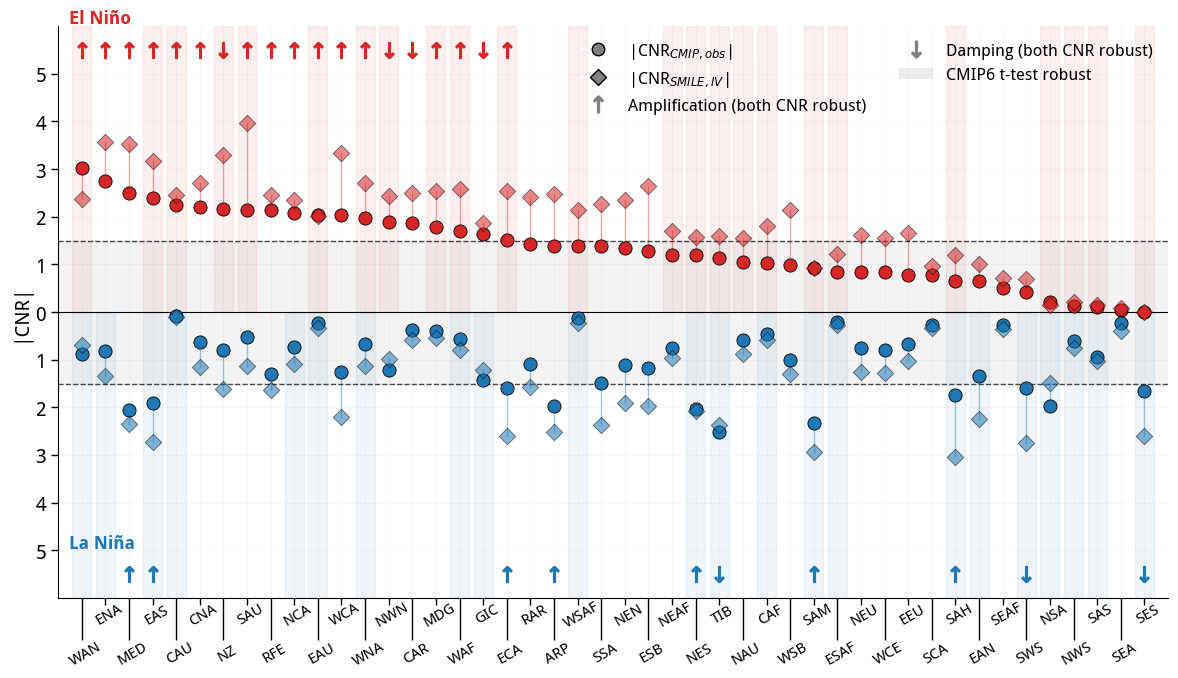

In [23]:
plot_snr_mirror(df, 'tas', '')

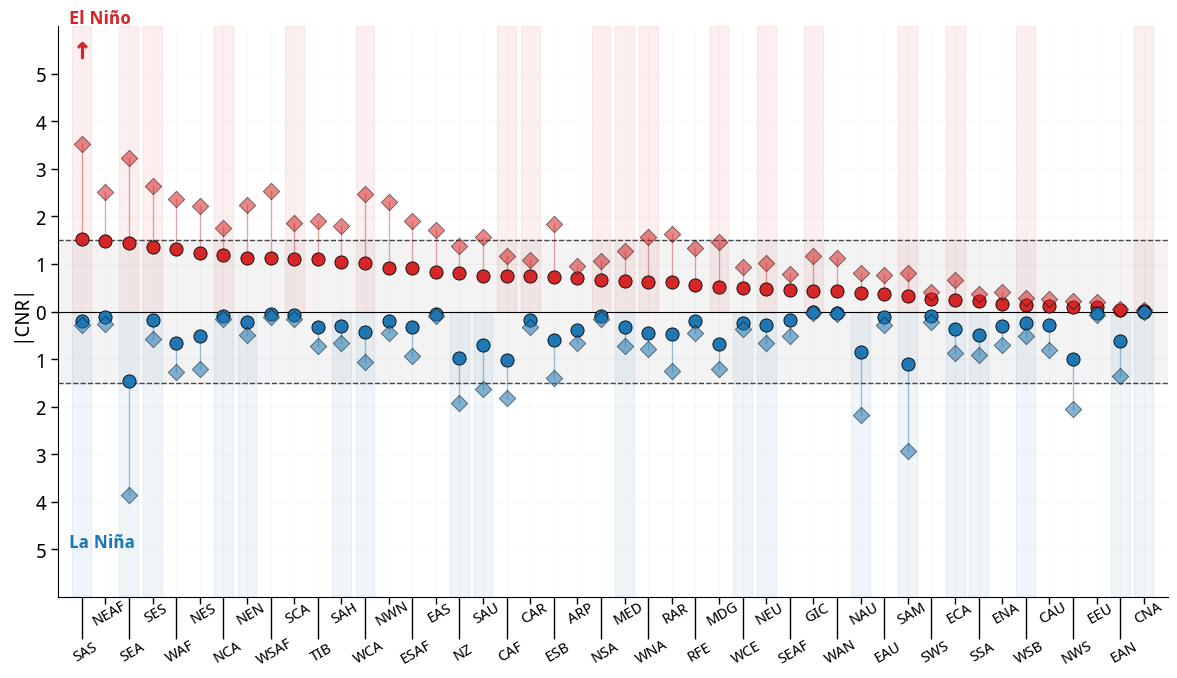

In [25]:

plot_snr_mirror(df, 'pr',  '')